# 06 · Avaliação da recuperação dos precedentes

Este notebook responde: **quando a regra que decide a pergunta está num precedente do TST, a base `lex_precedentes` entrega esse precedente?** E qual forma de busca funciona melhor nela?

**Dois gabaritos:**

| Gabarito | O que é | Tamanho | Peso |
|---|---|---|---|
| **A, especialista** | Perguntas reais da amostra do advogado revisor (notebook `03_integracao/04_avaliacao`), em que ele apontou o precedente do TST que decidia a pergunta. São as respostas que falharam por falta do precedente (notebook 00) | 7 perguntas (a 8ª depende do STF, fora desta base) | É o que mede o problema real, mas é pequeno |
| **B, prata (automático)** | Trechos de acórdãos da base de jurisprudência que citam **exatamente um** precedente do TST | 300 perguntas, de cerca de 150 precedentes | É grande, mas tem ruído: mede se a base acha o precedente pela descrição do caso |

**Como o gabarito B é montado:**
- A citação é mascarada: "Súmula nº 338 do TST" vira "[precedente]".
- Os 250 caracteres de cada lado da citação viram a pergunta.
- Trechos que **transcrevem** o texto do precedente, com 10 palavras seguidas iguais, são descartados, porque a busca estaria só copiando.
- Cada precedente entra no máximo 3 vezes, para que as súmulas processuais muito citadas, como a 333 e a 126, não dominem o conjunto.
- A seleção é determinística: os trechos são ordenados pelo hash do identificador.

**Buscas comparadas** (as mesmas peças da busca integrada):

| Busca | Como funciona |
|---|---|
| Semântica | BGE-M3, cosseno, 50 trechos |
| Por palavras | Texto normalizado, sem stopwords, peso IDF (notebook 05, seção 3), 50 trechos |
| Híbrida | Fusão das duas por RRF (k = 60) |
| Híbrida + reranker | Os 20 primeiros da híbrida reordenados pelo `bge-reranker-v2-m3`, que lê 256 tokens por par, como na busca integrada |

**Métricas**, contadas no nível do **precedente** (a unidade entregue ao modelo): Hit@1, Hit@3, Hit@5 e MRR@10. No gabarito A, também conferimos se o trecho que achou o precedente é o **item certo**, como a Súmula 338, I.

**Privacidade:** as perguntas da curadoria e os trechos dos acórdãos são usados só em memória. As tabelas e os CSVs mostram apenas identificadores, nomes de precedentes e posições.

### Dados desta etapa

| | Caminho no repositório | Formato | Quantidade | Versionado? |
|---|---|---|---|---|
| Entrada | PostgreSQL, schema `lex_precedentes` (notebook 05) | tabelas | 1.268 trechos · 1.493 registros | fora do Git (banco) |
| Entrada | `data/processed/precedentes/precedentes_tst.jsonl` | JSONL | 1.493 registros | fora do Git |
| Entrada (gabarito A) | `output/kaggle/geracao/dataset/pedidos.jsonl` | JSONL | 7 perguntas usadas (protegidas, só em memória) | fora do Git |
| Entrada (gabarito B) | PostgreSQL, `lex_jurisprudencia.embeddings` | tabela | 8.000 trechos candidatos, dos 303.257 | fora do Git (banco) |
| Relatórios | `reports/precedentes/avaliacao/` | CSV, JSON e PNG | gabarito_especialista.csv (7 linhas), gabarito_prata.csv (300), resultados_especialista.csv (7), resultados_prata.csv (300), metricas.csv (8), manifesto_avaliacao.json, metricas_por_busca.png | sim |

Os CSV levam só identificadores, nomes de precedentes e posições. O texto das perguntas e dos acórdãos não é gravado.

In [1]:
from pathlib import Path
import json, os, sys, hashlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/precedentes').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault('HF_HUB_OFFLINE', '1')
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 250); pd.set_option('display.max_columns', None)
import psycopg
from pgvector.psycopg import register_vector
from sentence_transformers import SentenceTransformer, CrossEncoder
from src.integracao.recuperacao import MODELO, REVISAO, RERANKER
from src.precedentes import indexacao as ix, avaliacao as av
from src.storage.pgvector_store import load_database_url

REL = ROOT / 'reports/precedentes/avaliacao'; REL.mkdir(parents=True, exist_ok=True)
registros = [json.loads(l) for l in (ROOT / 'data/processed/precedentes/precedentes_tst.jsonl').read_text(encoding='utf-8').splitlines() if l.strip()]
por_id = {r['id']: r for r in registros}
conexao = psycopg.connect(load_database_url(ROOT / '.env.pgvector.local'), autocommit=True)
register_vector(conexao)
dataset = conexao.execute("SELECT dataset_id FROM lex_precedentes.datasets WHERE estado='validado'").fetchone()[0]
man_ix = json.loads((ROOT / 'reports/precedentes/indexacao/manifesto_indexacao.json').read_text(encoding='utf-8'))
assert dataset == man_ix['dataset_id'], 'a versão validada no banco não é a do manifesto do notebook 05'
trechos = {c: dict(registro=r, texto=t, item=(m or {}).get('item')) for c, r, t, m in conexao.execute(
    'SELECT chunk_id, registro_id, texto, metadata FROM lex_precedentes.embeddings WHERE dataset_id=%s', (dataset,)).fetchall()}
chunk_reg = {c: v['registro'] for c, v in trechos.items()}
ix.preparar_lexico(conexao, dataset)
encoder = SentenceTransformer(MODELO, revision=REVISAO, device='cpu', local_files_only=True)
reranker = CrossEncoder(RERANKER, max_length=256, device='cpu', local_files_only=True)
print(f'lex_precedentes {dataset[:12]}… · {len(trechos)} trechos · {len(registros)} registros')

lex_precedentes bdf048e69083… · 1268 trechos · 1493 registros


## 1. As quatro buscas

In [2]:
METODOS = ['semântica', 'por palavras', 'híbrida', 'híbrida + reranker']

def buscar(pergunta, k=50, n_rerank=20):
    vetor = encoder.encode([pergunta], normalize_embeddings=True)[0].astype(np.float32)
    sem = [c for _, c, _ in ix.busca_semantica(conexao, dataset, vetor, k=k)]
    lex = [c for _, c, _ in ix.busca_lexical(conexao, dataset, pergunta, k=k)]
    hib = av.rrf([sem, lex])
    cand = hib[:n_rerank]
    notas = reranker.predict([(pergunta, trechos[c]['texto']) for c in cand], show_progress_bar=False) if cand else []
    rer = [c for _, c in sorted(zip(notas, cand), key=lambda x: (-x[0], x[1]))]
    return dict(zip(METODOS, [sem, lex, hib, rer]))

def posicao(chunks, esperado):
    ordem = av.ordem_registros(chunks, chunk_reg)
    return ordem.index(esperado) + 1 if esperado in ordem else None

def item_encontrado(chunks, esperado):
    """Item do primeiro trecho do precedente esperado na lista (None se o precedente não tem itens)."""
    return next((trechos[c]['item'] for c in chunks if chunk_reg[c] == esperado), None)
print('ok')

ok


## 2. Gabarito A: perguntas reais com o precedente apontado pelo advogado

São as perguntas da amostra do advogado em que a resposta falhou porque o sistema não tinha o precedente (notebook 00, seção 4). O texto delas é protegido e não aparece aqui.

In [3]:
GABARITO_A = [  # (pergunta_id, precedente esperado, item)
    ('juris_004', 'TST-SUM-338', 'I'), ('q09_p2_FAQ32', 'TST-SUM-276', None), ('juris_013', 'TST-SUM-378', 'II'),
    ('juris_019', 'TST-SUM-6', 'VIII'), ('juris_017', 'TST-IRR-58', None), ('q09_p1_JUS-001', 'TST-SUM-60', 'II'),
    ('q09_p2_FAQ26', 'TST-SUM-45', None)]
pedidos = {json.loads(l)['pergunta_id']: json.loads(l) for l in
           (ROOT / 'output/kaggle/geracao/dataset/pedidos.jsonl').read_text(encoding='utf-8').splitlines() if l.strip()}
linhas_a = []
for pid, esperado, item in GABARITO_A:
    res = buscar(pedidos[pid]['pergunta_sanitizada'])
    linha = dict(pergunta=pid, precedente=por_id[esperado]['nome_citacao'] + (f', {item}' if item else ''))
    for m in METODOS:
        linha[m] = posicao(res[m], esperado)
    achado = item_encontrado(res['híbrida + reranker'], esperado)
    linha['item certo (reranker)'] = None if item is None else (achado == item)
    linha['1º (reranker)'] = por_id[av.ordem_registros(res['híbrida + reranker'], chunk_reg)[0]]['nome_citacao']
    linhas_a.append(linha)
tab_a = pd.DataFrame(linhas_a)
display(tab_a)
met_a = pd.DataFrame({m: av.metricas([l[m] for l in linhas_a]) for m in METODOS}).T
display(met_a)
pd.DataFrame([dict(pergunta=p, esperado=e, item=i) for p, e, i in GABARITO_A]).to_csv(REL / 'gabarito_especialista.csv', index=False, encoding='utf-8')

,pergunta,precedente,semântica,por palavras,híbrida,híbrida + reranker,item certo (reranker),1º (reranker)
0,juris_004,"Súmula 338 do TST, I",1.0,1.0,1.0,1.0,False,Súmula 338 do TST
1,q09_p2_FAQ32,Súmula 276 do TST,2.0,33.0,3.0,1.0,None,Súmula 276 do TST
2,juris_013,"Súmula 378 do TST, II",3.0,1.0,1.0,1.0,True,Súmula 378 do TST
3,juris_019,"Súmula 6 do TST, VIII",1.0,9.0,1.0,1.0,False,Súmula 6 do TST
4,juris_017,Tema 58 de IRR do TST,1.0,1.0,1.0,1.0,None,Tema 58 de IRR do TST
5,q09_p1_JUS-001,"Súmula 60 do TST, II",3.0,NaN,21.0,NaN,False,Tema 92 de IRR do TST
6,q09_p2_FAQ26,Súmula 45 do TST,NaN,NaN,NaN,NaN,None,OJ 17 da SBDI-1 do TST


,Hit@1,Hit@3,Hit@5,MRR@10,n
semântica,0.429,0.857,0.857,0.595,7.0
por palavras,0.429,0.429,0.429,0.444,7.0
híbrida,0.571,0.714,0.714,0.619,7.0
híbrida + reranker,0.714,0.714,0.714,0.714,7.0


**Mesma súmula, duas bases.** No notebook 00, o texto destas súmulas, então digitado de memória, foi colocado entre os 20 mil acórdãos da base de jurisprudência. Aqui está a posição do texto oficial na base separada.

In [4]:
rank00 = pd.read_csv(ROOT / 'reports/precedentes/teste_ranking_jurisprudencia.csv')
comp = rank00[['pergunta_id', 'precedente', 'posicao_entre_documentos']].rename(
    columns={'pergunta_id': 'pergunta', 'posicao_entre_documentos': 'na base de jurisprudência (de 20 mil)'})
comp = comp.merge(tab_a[['pergunta', 'semântica', 'híbrida + reranker']].rename(
    columns={'semântica': 'em lex_precedentes: semântica', 'híbrida + reranker': 'em lex_precedentes: híbrida + reranker'}), on='pergunta')
display(comp)

,pergunta,precedente,na base de jurisprudência (de 20 mil),em lex_precedentes: semântica,em lex_precedentes: híbrida + reranker
0,juris_004,"Súmula 338, I, do TST",3370,1.0,1.0
1,q09_p2_FAQ32,Súmula 276 do TST,8,2.0,1.0
2,juris_013,"Súmula 378, II, do TST",864,3.0,1.0
3,juris_019,"Súmula 6, VIII, do TST",1459,1.0,1.0
4,q09_p1_JUS-001,Súmula 60 do TST,158,3.0,NaN


## 3. Gabarito B: trechos de acórdãos com a citação mascarada

**Seleção:**
- Os candidatos são os trechos da base de jurisprudência validada que mencionam súmula ou OJ seguidos de número. Eles são ordenados pelo hash do identificador e limitados aos 8 mil primeiros.
- Fica a primeira ocorrência de cada caso aceito, até 300 perguntas.
- A tabela de descartes mostra por que os outros saíram:
  - mais de um precedente citado no mesmo trecho;
  - precedente fora da busca (cancelado, suspenso ou em quarentena);
  - transcrição do texto do precedente;
  - excesso de ocorrências do mesmo precedente.

In [5]:
ds_jur = conexao.execute("SELECT dataset_id FROM lex_jurisprudencia.datasets WHERE estado='validado'").fetchone()[0]
candidatos = conexao.execute(r"""SELECT chunk_id, registro_id, texto FROM lex_jurisprudencia.embeddings WHERE dataset_id=%s
    AND texto ~* '(s[úu]mula|orienta[çc][ãa]o jurisprudencial|\moj\M)\s*(n[º°o.]*\s*)?\d{1,3}'
    ORDER BY md5(chunk_id) LIMIT 8000""", (ds_jur,)).fetchall()
itens_b, descartes = av.gabarito_prata(candidatos, registros, limite=300)
del candidatos
print(f'{len(itens_b)} perguntas · {len({i["esperado"] for i in itens_b})} precedentes distintos · '
      f'{len({i["acordao"] for i in itens_b})} acórdãos distintos')
display(pd.Series(descartes, name='trechos descartados').to_frame())
pd.DataFrame([{k: i[k] for k in ('id', 'chunk_origem', 'acordao', 'esperado', 'item', 'tipo')} for i in itens_b]).to_csv(
    REL / 'gabarito_prata.csv', index=False, encoding='utf-8')

300 perguntas · 156 precedentes distintos · 298 acórdãos distintos


,trechos descartados
varios_precedentes,361
nao_buscavel,111
transcricao,65
curto,0
excesso,1027


In [6]:
inicio = time.monotonic()
linhas_b = []
for i in itens_b:
    res = buscar(i['pergunta'])
    linha = dict(id=i['id'], esperado=i['esperado'], tipo=i['tipo'])
    for m in METODOS:
        linha[m] = posicao(res[m], i['esperado'])
    linha['1º (reranker)'] = (av.ordem_registros(res['híbrida + reranker'], chunk_reg) or [None])[0]
    linha['1º (híbrida)'] = (av.ordem_registros(res['híbrida'], chunk_reg) or [None])[0]
    linhas_b.append(linha)
tab_b = pd.DataFrame(linhas_b)
print(f'{len(tab_b)} perguntas em {time.monotonic() - inicio:.0f} s')
met_b = pd.DataFrame({m: av.metricas(tab_b[m].tolist()) for m in METODOS}).T
display(met_b)
por_tipo = pd.DataFrame({(t, m): av.metricas(tab_b[tab_b.tipo == t][m].tolist()) for t in ['sumula', 'orientacao_jurisprudencial'] for m in METODOS}).T[['Hit@1', 'Hit@3', 'MRR@10', 'n']]
display(por_tipo)

300 perguntas em 5895 s


,Hit@1,Hit@3,Hit@5,MRR@10,n
semântica,0.293,0.460,0.547,0.399,300.0
por palavras,0.167,0.303,0.367,0.247,300.0
híbrida,0.267,0.433,0.487,0.372,300.0
híbrida + reranker,0.327,0.533,0.597,0.442,300.0


Hit@1  Hit@3  MRR@10      n
sumula                     semântica           0.278  0.453   0.387  212.0
                           por palavras        0.127  0.264   0.211  212.0
                           híbrida             0.231  0.401   0.340  212.0
                           híbrida + reranker  0.307  0.519   0.424  212.0
orientacao_jurisprudencial semântica           0.330  0.477   0.428   88.0
                           por palavras        0.261  0.398   0.336   88.0
                           híbrida             0.352  0.511   0.450   88.0
                           híbrida + reranker  0.375  0.568   0.486   88.0

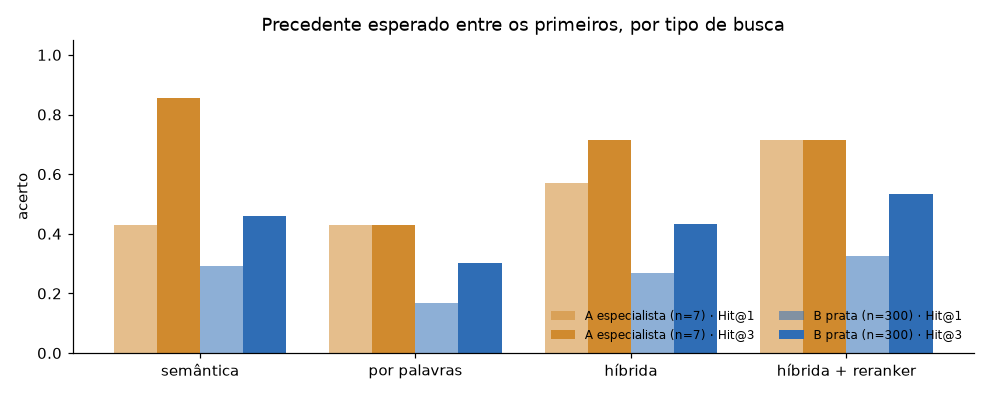

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(METODOS)); w = 0.2
for j, (g, met, cor) in enumerate([('A especialista (n=7)', met_a, '#d08a2e'), ('B prata (n=%d)' % len(tab_b), met_b, '#2f6db5')]):
    for k, (col, alfa) in enumerate([('Hit@1', .55), ('Hit@3', 1.0)]):
        pos = x + (j * 2 + k - 1.5) * w
        ax.bar(pos, met[col].values, w, color=cor, alpha=alfa, label=f'{g} · {col}')
ax.set_xticks(x, METODOS); ax.set_ylim(0, 1.05); ax.set_ylabel('acerto')
ax.set_title('Precedente esperado entre os primeiros, por tipo de busca')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(REL / 'metricas_por_busca.png', dpi=110)
display(fig); plt.close(fig)

## 4. Quando erra, o que vem em primeiro?

Nos erros do gabarito B, comparamos o precedente esperado com o que ficou em 1º. Muitas vezes o 1º é um precedente vizinho, do mesmo assunto ou do mesmo dispositivo. Nesse caso, o erro pesa menos para a resposta, porque o modelo recebe 3 precedentes.

In [8]:
melhor = met_b['MRR@10'].idxmax()
col1 = '1º (reranker)' if melhor == 'híbrida + reranker' else '1º (híbrida)'
erros = tab_b[(tab_b[melhor] != 1)]
print(f'Busca de referência: {melhor} · erros no 1º lugar: {len(erros)} de {len(tab_b)} '
      f'(o esperado aparece até o 3º em {int((erros[melhor] <= 3).sum())}; não aparece até o 10º em {int(erros[melhor].isna().sum() + (erros[melhor] > 10).sum())})')
amostra = erros.head(12).assign(
    esperado_nome=lambda d: d.esperado.map(lambda r: por_id[r]['nome_citacao'] + ' — ' + por_id[r]['titulo'][:50]),
    primeiro_nome=lambda d: d[col1].map(lambda r: por_id[r]['nome_citacao'] + ' — ' + por_id[r]['titulo'][:50] if r else None))
display(amostra[['id', 'esperado_nome', 'primeiro_nome', melhor]])

Busca de referência: híbrida + reranker · erros no 1º lugar: 202 de 300 (o esperado aparece até o 3º em 62; não aparece até o 10º em 103)


,id,esperado_nome,primeiro_nome,híbrida + reranker
0,prata-ee2fcfc15131,Súmula 128 do TST — DEPÓSITO RECURSAL,OJ 260 da SBDI-1 do TST — AGRAVO DE INSTRUMENTO. RECURSO DE REVISTA. PROCEDI,NaN
1,prata-a8b9542bda6c,Súmula 422 do TST — RECURSO. FUNDAMENTO AUSENTE OU DEFICIENTE. NÃO CON,OJ 260 da SBDI-1 do TST — AGRAVO DE INSTRUMENTO. RECURSO DE REVISTA. PROCEDI,NaN
3,prata-184a67a63d12,Súmula 393 do TST — RECURSO ORDINÁRIO. EFEITO DEVOLUTIVO EM PROFUNDIDA,Súmula 331 do TST — CONTRATO DE PRESTAÇÃO DE SERVIÇOS. LEGALIDADE,NaN
4,prata-f7f75221bc17,Súmula 126 do TST — RECURSO. CABIMENTO,OJ 260 da SBDI-1 do TST — AGRAVO DE INSTRUMENTO. RECURSO DE REVISTA. PROCEDI,4.0
5,prata-b300d00ced7c,Súmula 333 do TST — RECURSOS DE REVISTA. CONHECIMENTO,"OJ 147 da SBDI-1 do TST — LEI ESTADUAL, NORMA COLETIVA OU NORMA REGULAMENTAR",4.0
7,prata-fc7a7eb0551e,Súmula 331 do TST — CONTRATO DE PRESTAÇÃO DE SERVIÇOS. LEGALIDADE,Tema 59 de IRR do TST — CONTRATO DE TRANSPORTE DE CARGAS/MERCADORIAS. TERC,4.0
10,prata-bcf53f5f3826,Súmula 126 do TST — RECURSO. CABIMENTO,Súmula 331 do TST — CONTRATO DE PRESTAÇÃO DE SERVIÇOS. LEGALIDADE,NaN
11,prata-07b7cc611791,Súmula 51 do TST — NORMA REGULAMENTAR. VANTAGENS E OPÇÃO PELO NOVO RE,Tema 300 de IRR do TST — TRABALHO EXTERNO. AUSÊNCIA DE CONTROLE. PREVISÃO E,NaN
12,prata-0572d2f797a2,OJ 191 da SBDI-1 do TST — CONTRATO DE EMPREITADA. DONO DA OBRA DE CONSTRUÇÃO,OJ 32 da SBDI-1 (transitória) do TST — COMPLEMENTAÇÃO DE APOSENTADORIA. BANC...,NaN
14,prata-afe9e73fc249,Súmula 438 do TST — INTERVALO PARA RECUPERAÇÃO TÉRMICA DO EMPREGADO. A,Tema 211 de IRR do TST — INTERVALO PARA RECUPERAÇÃO TÉRMICA. TRABALHO EM AM,2.0


## 5. Gravação

In [9]:
tab_a.to_csv(REL / 'resultados_especialista.csv', index=False, encoding='utf-8')
tab_b.to_csv(REL / 'resultados_prata.csv', index=False, encoding='utf-8')
metricas = pd.concat([met_a.assign(gabarito='A especialista'), met_b.assign(gabarito='B prata')]).rename_axis('busca').reset_index()
metricas.to_csv(REL / 'metricas.csv', index=False, encoding='utf-8')
(REL / 'manifesto_avaliacao.json').write_text(json.dumps(dict(
    dataset_precedentes=dataset, dataset_jurisprudencia=ds_jur, modelo=f'{MODELO}@{REVISAO}', reranker=RERANKER,
    reranker_max_length=256, rrf_k=av.RRF_K, n_rerank=20, janela_caracteres=av.JANELA, max_por_precedente=av.MAX_POR_PRECEDENTE,
    gabarito_especialista=len(tab_a), gabarito_prata=len(tab_b), descartes_prata=descartes), indent=2, ensure_ascii=False), encoding='utf-8')
display(metricas)

,busca,Hit@1,Hit@3,Hit@5,MRR@10,n,gabarito
0,semântica,0.429,0.857,0.857,0.595,7.0,A especialista
1,por palavras,0.429,0.429,0.429,0.444,7.0,A especialista
2,híbrida,0.571,0.714,0.714,0.619,7.0,A especialista
3,híbrida + reranker,0.714,0.714,0.714,0.714,7.0,A especialista
4,semântica,0.293,0.460,0.547,0.399,300.0,B prata
5,por palavras,0.167,0.303,0.367,0.247,300.0,B prata
6,híbrida,0.267,0.433,0.487,0.372,300.0,B prata
7,híbrida + reranker,0.327,0.533,0.597,0.442,300.0,B prata


## Conclusões

1. **A base separada resolve o problema do notebook 00.** No gabarito A, a busca híbrida + reranker põe em 1º lugar 5 dos 7 precedentes que faltaram nas respostas reprovadas pelo advogado: Súmulas 338, 276, 378 e 6, e Tema 58. Na base de jurisprudência, essas súmulas ficavam entre a 8ª e a 3.370ª posição. A busca só semântica acha 6 dos 7 até o 3º lugar.
2. **As duas falhas do gabarito A apontam ajustes concretos:**
   - **Súmula 60:** a busca semântica a punha em 3º, mas a fusão com a busca por palavras a levou ao 21º lugar. Como o reranker só reordena os 20 primeiros, ela ficou de fora. **Ajuste:** montar o conjunto do reranker com a união dos primeiros de cada busca, e não só com os primeiros da fusão.
   - **Súmula 45:** nenhuma busca achou. A pergunta fala em "13º salário" e a súmula, em "gratificação natalina", um sinônimo jurídico que nem o vetor nem as palavras ligaram. **Ajuste:** um dicionário de sinônimos jurídicos na normalização da pergunta, como "13º salário" = "gratificação natalina", "DSR" = "repouso semanal remunerado" e "FGTS" = "fundo de garantia".
3. **No gabarito B, a híbrida + reranker é a melhor:**
   - Hit@1 de 0,33, Hit@3 de 0,53 e MRR de 0,44;
   - em seguida vem a semântica, com 0,29, 0,46 e 0,40;
   - a busca por palavras sozinha é a mais fraca (0,17 e 0,30). Na fusão, ela deixa a híbrida sem reranker abaixo da semântica (0,27 e 0,43), e o reranker recupera.
4. **O gabarito B é conservador:**
   - muitos erros são súmulas processuais, como as 126, 333, 422 e 128, sobre o cabimento de recurso. O texto delas pouco descreve o caso, e o acórdão as cita de passagem;
   - parte dos "erros" é um precedente vizinho também correto, como a Súmula 438 e o Tema 211, ambos sobre o intervalo para recuperação térmica.
5. **Item certo:** nas súmulas com itens, o primeiro trecho encontrado nem sempre é o item da pergunta (foi o item certo em 1 dos 3 casos em que a súmula veio). Como o modelo recebe o **registro inteiro**, o item certo chega mesmo assim. Mas a busca ainda não distingue bem os itens.
6. **Recomendação para integrar a base como terceira fonte:**
   - usar a busca **híbrida + reranker**, com o conjunto do reranker vindo da **união** dos primeiros da semântica e da busca por palavras;
   - começar com uma **cota de 3 precedentes**, pelo Hit@3;
   - testar no conjunto maior de perguntas, junto com os sinônimos jurídicos.
7. **Limitações:**
   - o gabarito A tem só 7 perguntas, e cada uma vale 14 pontos percentuais;
   - o gabarito B é automático: um precedente igualmente correto conta como erro;
   - o tempo é alto: cerca de 16 s por pergunta na CPU, sobretudo por causa do reranker. Na busca integrada, ele reordena só 20 trechos por fonte.

## 6. Gráficos das comparações

Os gráficos abaixo mostram as comparações das seções 2 e 3. Eles leem os resultados gravados na seção 5 (`reports/precedentes/avaliacao/*.csv`), sem refazer as buscas, e gravam as imagens na mesma pasta.

1. **Gabarito A, pergunta a pergunta:** a posição do precedente que o advogado apontou, em cada uma das quatro buscas. Quanto mais escuro, mais perto do 1º lugar; cinza é fora dos 10 primeiros.
2. **Mesma súmula, duas bases:** a posição da súmula entre as 20 mil decisões da base de jurisprudência (notebook 00) e na base `lex_precedentes`, com a busca híbrida + reranker.
3. **Gabarito B, distribuição:** em quantos dos 300 trechos o precedente esperado vem em 1º, entre o 2º e o 3º, entre o 4º e o 10º, ou fora dos 10.
4. **Gabarito B por tipo:** a qualidade da ordenação (MRR@10) separada para súmulas e orientações jurisprudenciais.


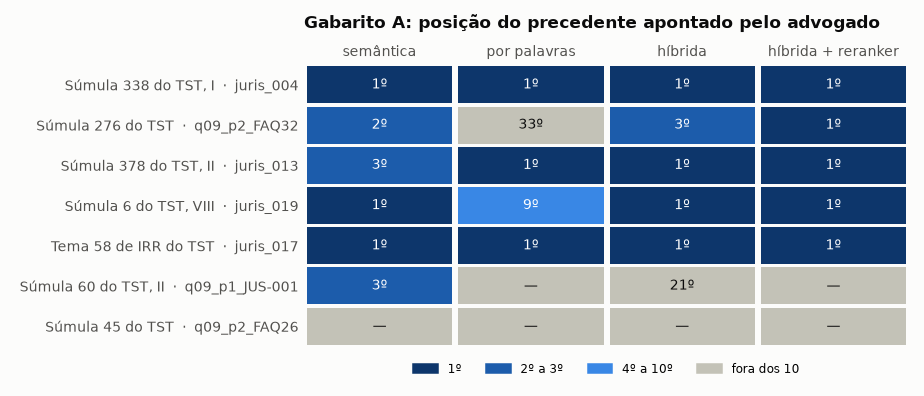

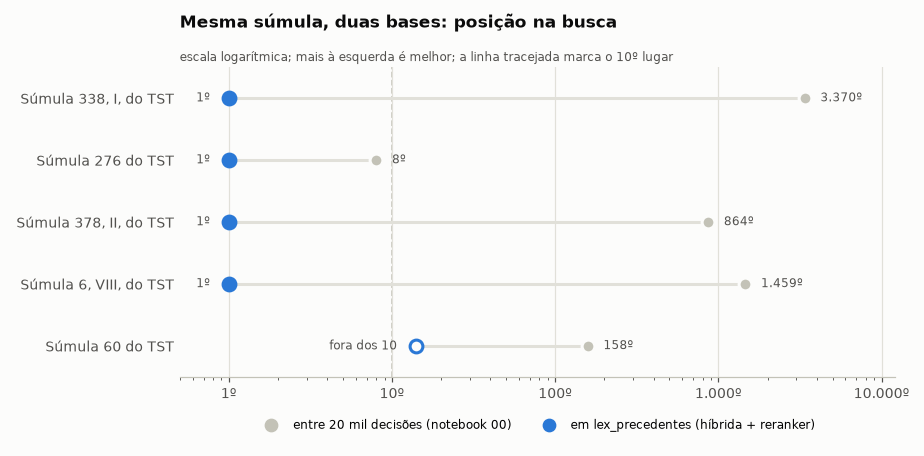

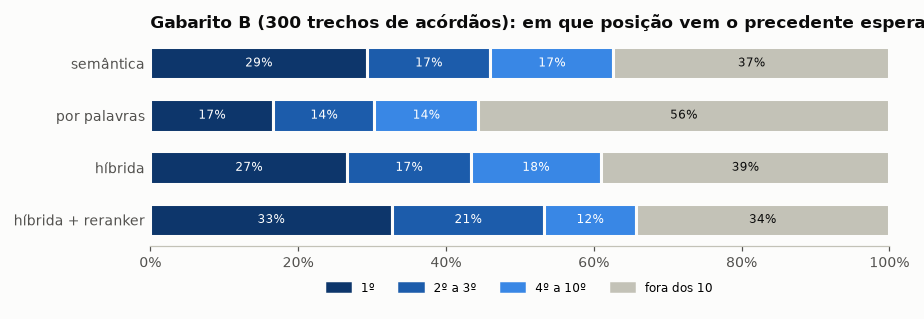

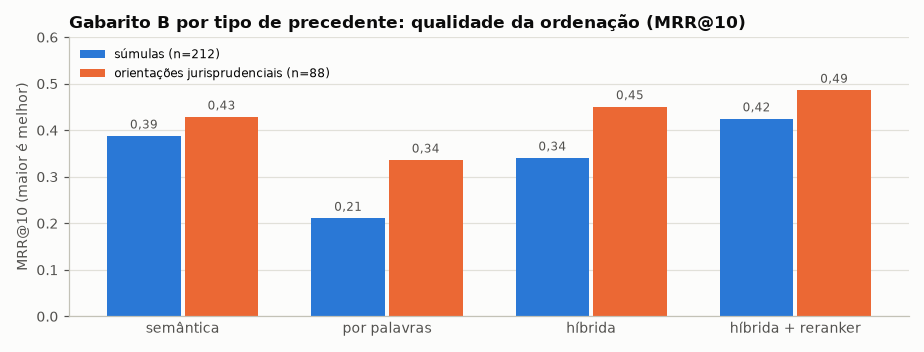

In [ ]:
# Gráficos das comparações: lê os resultados gravados na seção 5 (não refaz as buscas).
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/precedentes').exists())
REL = ROOT / 'reports/precedentes/avaliacao'
METODOS = ['semântica', 'por palavras', 'híbrida', 'híbrida + reranker']
tab_a = pd.read_csv(REL / 'resultados_especialista.csv')
tab_b = pd.read_csv(REL / 'resultados_prata.csv')
rank00 = pd.read_csv(ROOT / 'reports/precedentes/teste_ranking_jurisprudencia.csv')

# Cores (paleta de referência validada): faixas de posição = rampa ordinal azul; "fora dos 10" = cinza neutro.
TINTA, TINTA2, EIXO, GRADE, FUNDO = '#0b0b0b', '#52514e', '#c3c2b7', '#e1e0d9', '#fcfcfb'
FAIXAS = [('1º', '#0d366b'), ('2º a 3º', '#1c5cab'), ('4º a 10º', '#3987e5'), ('fora dos 10', '#c3c2b7')]
COR_SUM, COR_OJ = '#2a78d6', '#eb6834'
plt.rcParams.update({'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': TINTA, 'font.size': 9,
                     'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'savefig.facecolor': FUNDO})

def faixa(pos):
    if pd.isna(pos) or pos > 10:
        return 3
    return 0 if pos == 1 else 1 if pos <= 3 else 2

def limpar(ax, grade='x'):
    ax.spines[['top', 'right']].set_visible(False)
    if grade:
        ax.grid(axis=grade, color=GRADE, linewidth=0.8); ax.set_axisbelow(True)

legenda_faixas = [Patch(color=c, label=n) for n, c in FAIXAS]

# 1. Gabarito A: posição do precedente esperado, pergunta a pergunta.
fig, ax = plt.subplots(figsize=(8.4, 3.6))
for i, r in tab_a.iterrows():
    for j, m in enumerate(METODOS):
        f = faixa(r[m])
        ax.add_patch(plt.Rectangle((j + 0.02, i + 0.04), 0.96, 0.92, color=FAIXAS[f][1], linewidth=0))
        txt = '—' if pd.isna(r[m]) else f'{int(r[m])}º'
        ax.text(j + 0.5, i + 0.5, txt, ha='center', va='center', fontsize=9,
                color='#ffffff' if f < 3 else TINTA)
ax.set_xlim(0, len(METODOS)); ax.set_ylim(len(tab_a), 0)
ax.set_xticks(np.arange(len(METODOS)) + 0.5, METODOS); ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_yticks(np.arange(len(tab_a)) + 0.5, [f"{p}  ·  {q}" for p, q in zip(tab_a.precedente, tab_a.pergunta)])
ax.spines[:].set_visible(False)
ax.set_title('Gabarito A: posição do precedente apontado pelo advogado', pad=24, loc='left')
ax.legend(handles=legenda_faixas, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.02), fontsize=8)
fig.tight_layout(); fig.savefig(REL / 'grafico_especialista_posicoes.png', dpi=110); display(fig); plt.close(fig)

# 2. Mesma súmula, duas bases: posição na base de jurisprudência (notebook 00) e em lex_precedentes.
comp = rank00[['pergunta_id', 'precedente', 'posicao_entre_documentos']].merge(
    tab_a[['pergunta', 'híbrida + reranker']], left_on='pergunta_id', right_on='pergunta')
fig, ax = plt.subplots(figsize=(8.4, 1.4 + 0.55 * len(comp)))
FORA = 14          # 'fora dos 10': marcador vazado logo depois da linha do 10º
for i, r in enumerate(comp.itertuples()):
    novo = r[-1]                                   # coluna 'híbrida + reranker'
    x_novo = FORA if pd.isna(novo) else novo
    ax.plot([x_novo, r.posicao_entre_documentos], [i, i], color=GRADE, linewidth=2, zorder=1)
    ax.scatter(r.posicao_entre_documentos, i, s=70, color=EIXO, edgecolor=FUNDO, linewidth=2, zorder=2)
    ax.scatter(x_novo, i, s=70, color=COR_SUM if not pd.isna(novo) else FUNDO,
               edgecolor=COR_SUM, linewidth=2, zorder=3)
    ax.text(r.posicao_entre_documentos * 1.25, i, f'{int(r.posicao_entre_documentos):,}º'.replace(',', '.'), va='center',
            color=TINTA2, fontsize=8)
    ax.text(x_novo / 1.3, i, 'fora dos 10' if pd.isna(novo) else f'{int(novo)}º', va='center', ha='right',
            color=TINTA2, fontsize=8)
ax.set_xscale('log'); ax.set_xlim(0.5, 12000); ax.set_ylim(len(comp) - 0.5, -0.5)
ax.axvline(10, color=EIXO, linestyle='--', linewidth=1, zorder=0)
ax.set_yticks(range(len(comp)), comp.precedente); ax.tick_params(axis='y', length=0)
ax.set_xticks([1, 10, 100, 1000, 10000], ['1º', '10º', '100º', '1.000º', '10.000º'])
limpar(ax); ax.spines['left'].set_visible(False)
ax.set_title('Mesma súmula, duas bases: posição na busca', loc='left', pad=26)
ax.text(0, 1.02, 'escala logarítmica; mais à esquerda é melhor; a linha tracejada marca o 10º lugar',
        transform=ax.transAxes, fontsize=8, color=TINTA2)
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=EIXO, markersize=8, label='entre 20 mil decisões (notebook 00)'),
                   plt.Line2D([], [], marker='o', ls='', color=COR_SUM, markersize=8, label='em lex_precedentes (híbrida + reranker)')],
          frameon=False, fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(); fig.savefig(REL / 'grafico_duas_bases.png', dpi=110); display(fig); plt.close(fig)

# 3. Gabarito B: distribuição da posição do esperado, por busca (300 trechos de acórdãos).
fig, ax = plt.subplots(figsize=(8.4, 2.9))
for i, m in enumerate(METODOS):
    cont = tab_b[m].map(faixa).value_counts().reindex(range(4), fill_value=0) / len(tab_b)
    inicio = 0
    for f, v in cont.items():
        ax.barh(i, v, left=inicio, height=0.62, color=FAIXAS[f][1], edgecolor=FUNDO, linewidth=2)
        if v >= 0.07:
            ax.text(inicio + v / 2, i, f'{v:.0%}', ha='center', va='center', fontsize=8,
                    color='#ffffff' if f < 3 else TINTA)
        inicio += v
ax.set_yticks(range(len(METODOS)), METODOS); ax.set_ylim(len(METODOS) - 0.5, -0.5); ax.tick_params(axis='y', length=0)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
limpar(ax, grade=None); ax.spines['left'].set_visible(False)
ax.set_title(f'Gabarito B ({len(tab_b)} trechos de acórdãos): em que posição vem o precedente esperado', loc='left')
ax.legend(handles=legenda_faixas, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=8)
fig.tight_layout(); fig.savefig(REL / 'grafico_prata_posicoes.png', dpi=110); display(fig); plt.close(fig)

# 4. Gabarito B por tipo de precedente: súmulas e orientações jurisprudenciais (MRR@10).
def mrr(s):
    return float(np.mean([1 / p if not pd.isna(p) and p <= 10 else 0 for p in s]))
tipos = [('sumula', 'súmulas', COR_SUM), ('orientacao_jurisprudencial', 'orientações jurisprudenciais', COR_OJ)]
fig, ax = plt.subplots(figsize=(8.4, 3.2))
x = np.arange(len(METODOS)); w = 0.36
for k, (t, nome, cor) in enumerate(tipos):
    sub = tab_b[tab_b.tipo == t]
    vals = [mrr(sub[m]) for m in METODOS]
    pos = x + (k - 0.5) * (w + 0.02)
    ax.bar(pos, vals, w, color=cor, label=f'{nome} (n={len(sub)})')
    for px, v in zip(pos, vals):
        ax.text(px, v + 0.01, f'{v:.2f}'.replace('.', ','), ha='center', va='bottom', fontsize=8, color=TINTA2)
ax.set_xticks(x, METODOS); ax.set_ylim(0, 0.6); ax.set_ylabel('MRR@10 (maior é melhor)')
limpar(ax, grade='y'); ax.tick_params(axis='x', length=0)
ax.set_title('Gabarito B por tipo de precedente: qualidade da ordenação (MRR@10)', loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(REL / 'grafico_prata_por_tipo.png', dpi=110); display(fig); plt.close(fig)
